# Riesz — space-summed medium EP fluctuations

같은 source 거리 rho의 EP를 모두 합한 뒤 variation을 그리는 전용 노트북. 기존 baseline trajectory를 사용하므로 추가 시뮬레이션 없이 실행된다.

## 같은 rho의 medium EP를 먼저 합산

$$j_{K,\rho}(t_j)=\sum_bJ_{b\rho}(t_j)
=\frac{\Delta V}{\delta t}\sum_{n\in j,x}\Delta s_{K,\rho}(x),$$
$$j_{\mathrm{med},\rho}(t)=j_{K,\rho}(t)
+\mathbf1_{\rho=0}[j_{C,\mathrm{local}}(t)+j_A(t)].$$

각 $\rho$의 **모든 위치와 receiving phi bin의 signed EP를 먼저 합산**한다.
그 시간 신호의 variation은
$$\mathrm{Var}_t[j_{\mathrm{med},\rho}],\qquad
\sigma_\rho=\sqrt{\mathrm{Var}_t[j_{\mathrm{med},\rho}]}$$
이다. Local conservative/active 항은 $\rho=0$에만 넣어
$\sum_\rho j_{\mathrm{med},\rho}=j_{\mathrm{med}}$를 만족시킨다.
그림은 nonlocal $\rho>0$를 그리고 $\rho=0$ 값도 따로 출력한다.

기본값은 **총합 EP rate**이며 `PER_AREA=True`로 바꾸면 총합 뒤에 box area로 나눈다.
`AS_INCREMENT=True`는 rate 대신 저장 시간 구간의 entropy increment를 분석한다.
물리적인 sampling interval을 고정하여 곡선을 비교한다.

## 보조 진단: 누적 source 거리 cutoff R

$$j_{\le R}(t)=j_{C,\mathrm{local}}(t)+j_A(t)+\sum_{\rho\le R}j_{K,\rho}(t),$$
$$\mathrm{Var}[j_{\le R}]=\sum_{\rho,\rho'\le R}\mathrm{Cov}(j_\rho,j_{\rho'}).$$

**동일한 dynamics/trajectory에서 포함하는 kernel 거리 범위**를 늘리며 총 fluctuation이 어떻게
변하는지 본다. 거리 사이의 음/양의 상관 때문에 누적 variance는 단조일 필요가 없다.
모든 range에서 rate를 먼저 합한 뒤 variance/PSD를 계산한다.
여기서 R은 관측량의 포함 범위이다. Poisson/Linnik의 실제 interaction range는 kernel.ell이며,
별도 poisson_ep/linnik_ep 노트북에서 ell별로 새 trajectory를 적분한다.

불확실도는 시간 block을 모든 rho에 대해 함께 bootstrap하여 구한다. 거리별 trend는
선택한 rho window의 경험적 log(std) slope와 그 block-bootstrap interval로 표시한다.
드리프트나 긴 상관이 있으면 이 값은 finite-window 진단이다.


In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd()
if not (ROOT/'lramb').is_dir():
    ROOT=next((q for q in [ROOT/'LRAMB',*ROOT.parents] if (q/'lramb').is_dir()),ROOT)
sys.path.insert(0,str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from lramb import Run,simulate
from lramb.ep_ranges import (ShellEP,shell_summary,plot_shell_summary,
    plot_cumulative_ranges,save_shell_summary,decay_diagnostic)
from lramb.analysis import stationarity_report
from lramb import ActiveModelB,Parameters,KernelSpec
from lramb import backend_options
from lramb.scaling import plot_scaling_comparison

KIND='riesz'
PER_AREA=False          # signed space SUM first; optional constant area normalization afterwards
AS_INCREMENT=False     # False: EP rate; True: entropy increment over sampling interval
BOOTSTRAP_BLOCKS=8
BOOTSTRAP_DRAWS=500
FIT_RHO_MIN=2.0
FIT_RHO_MAX=16.0        # exclude rho=0 and the torus corner region
SIMULATION=backend_options('auto',device='auto',dtype='float64')  # 'torch' also enables torch CPU
SOURCE_FOLDER=ROOT/'results'/KIND  # use f'{KIND}_torch' for the command-line torch run
OUTPUT=ROOT/'results'/f'{KIND}_ep'
OUTPUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':105,'font.size':10})


## 1. 공간 합산한 rho 신호

기존 baseline의 full-step midpoint EP를 사용한다. Kernel은 quadratic이므로 공간을 합한
거리 shell의 midpoint EP는 해당 shell 자유에너지의 차이와 정확히 같다.
이를 이용해 grid 간격 dx의 세밀한 rho shell 신호를 복원한다.
원래 phi-resolved decomposition의 12개 coarse shell보다 rho 해상도가 높다.


In [2]:
source_folder = SOURCE_FOLDER
run_path = source_folder/'trajectory.npz'
if not run_path.exists():
    print('No cached trajectory: running the 64x64 Euler-Maruyama baseline.')
    fallback_p=Parameters()
    fallback_kernel=KernelSpec(KIND,alpha=1.5 if KIND=='linnik' else 1.0)
    fallback_model=ActiveModelB(fallback_p,fallback_kernel)
    initial_mode='random' if KIND=='riesz' else 'stripe'
    fallback_run=simulate(fallback_model,initial=fallback_model.initial_field(initial_mode),progress=True,**SIMULATION)
    fallback_run.metadata['initial_mode']=initial_mode
    fallback_run.save(run_path)
run = Run.load(run_path)
if run.metadata['kernel']['kind'] != KIND:
    raise ValueError('The cached trajectory belongs to a different kernel')
series = ShellEP.from_run(run)
# Fine source shells are [rho-dx/2, rho+dx/2), including rho=0.
# Quadratic K gives exactly sum_n midpoint EP = -Delta F_rho/D.
# Full-precision shell energies are used, rather than sparse float32 field differences.
ep_atol=1e-8 if run.metadata.get('dtype','float64')=='float64' else 1e-2
ep_rtol=1e-7 if run.metadata.get('dtype','float64')=='float64' else 5e-4
np.testing.assert_allclose(series.lr_rate.sum(axis=1),run.ep_rate[:,1],atol=ep_atol,rtol=ep_rtol)
np.testing.assert_allclose(series.medium_rate.sum(axis=1),run.ep_rate.sum(axis=1),atol=ep_atol,rtol=ep_rtol)
print('Kernel:', run.metadata['kernel'])
print('Integrator:', run.metadata['integrator'], '; entropy:', run.metadata['entropy_convention'])
print('EP intervals:',len(series.time), '; sampling interval:', series.metadata['interval'])
print('Max reconstruction error:',np.max(abs(series.medium_rate.sum(axis=1)-run.ep_rate.sum(axis=1))))
print('Source distance bins:',series.rho)
series.save(OUTPUT/'rho_ep_time_series.npz')


Kernel: {'kind': 'riesz', 'strength': 0.35, 'ell': 2.0, 'alpha': 1.0}
Integrator: Euler-Maruyama ; entropy: midpoint for all terms
EP intervals: 1600 ; sampling interval: 0.4
Max reconstruction error: 4.064304448547773e-11
Source distance bins: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
 36. 37. 38. 39. 40. 41. 42. 43. 44. 45.]


## 2. 같은 rho에서 합산한 뒤 variance / standard deviation

평균은 먼저 제거한다. 신뢰구간은 rho를 함께 유지하며 time block을 bootstrap한 결과이다. 거리별 값이 줄어드는지 Std/Variance 곡선과 rho-window trend를 함께 확인한다. 그래프는 감소를 강제하지 않는다.

{'rho_min': 2.0,
 'rho_max': 16.0,
 'log_std_slope': -1.5000058424407987,
 'log_std_slope_ci95': [-1.520165711515993, -1.4808651843421512],
 'spearman_rho': -0.9607142857142855,
 'decreasing_adjacent_fraction': 0.8571428571428571,
 'interpretation': 'decreasing over this rho window'}

rho=0 (local conservative + active + on-site K) Std: 180.12096059708213
Total medium EP Std: 176.56109880179426


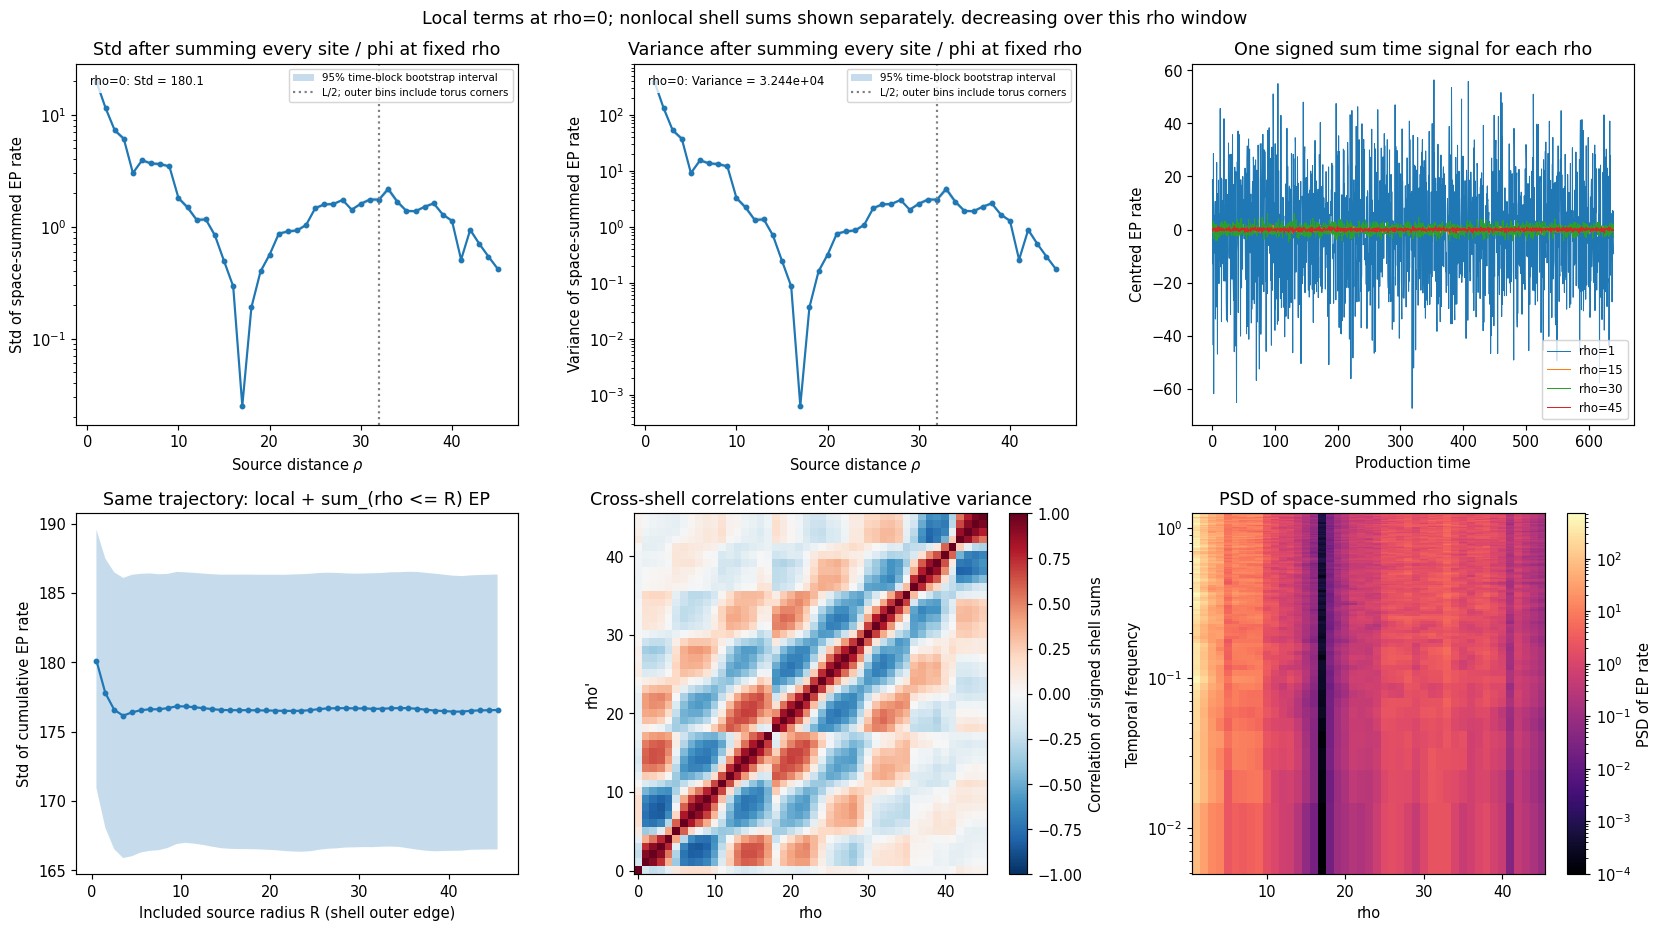

In [3]:
summary=shell_summary(series,blocks=BOOTSTRAP_BLOCKS,draws=BOOTSTRAP_DRAWS,
                      density=PER_AREA,increment=AS_INCREMENT)
fig_rho,decay=plot_shell_summary(series,summary,OUTPUT,
    rho_min=FIT_RHO_MIN,rho_max=FIT_RHO_MAX)
display(decay)
print('rho=0 (local conservative + active + on-site K) Std:',summary['shell']['std'][0])
print('Total medium EP Std:',summary['cumulative']['std'][-1])
save_shell_summary(series,summary,OUTPUT/'rho_ep_fluctuations.npz')
plt.show()


## 3. 보조 진단: 누적 source 거리 cutoff R

동일 trajectory에서 kernel 기여를 거리 R까지 포함한다. Medium 전체와 kernel 기여를 각각 합산해 Std를 비교하고, 선택한 R의 시간 신호와 PSD를 표시한다. 이 비교에서는 kernel이나 trajectory를 재계산하지 않는다.

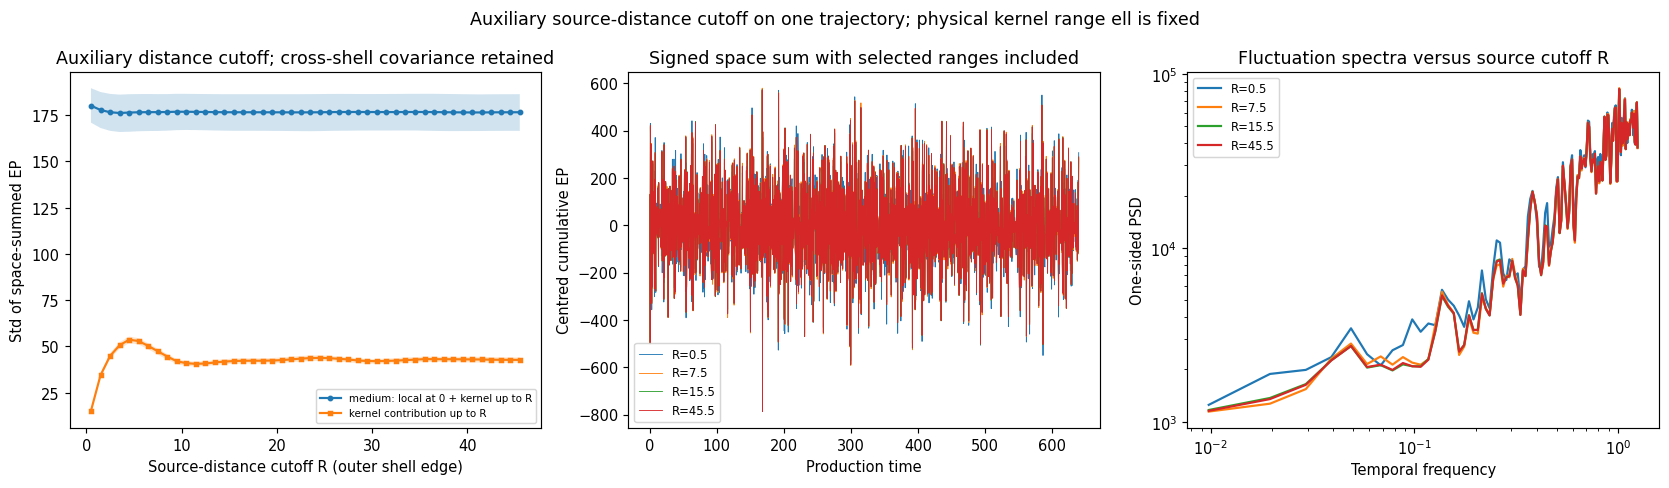

In [4]:
fig_range,kernel_cumulative=plot_cumulative_ranges(series,summary,OUTPUT)
plt.show()


## 4. Variance / rho²와 density 2-point scaling 비교

$$V_2(\rho)=\mathrm{Var}_t[j_{\mathrm{med},\rho}]/\rho^2,\qquad\rho>0,$$
$$C(\rho)=\langle[\phi(x,t)-\bar\phi][\phi(x+r,t)-\bar\phi]\rangle_{x,t,|r|\in B_\rho}.$$

EP는 **공간 합산 후** variance를 계산하며, C는 각 거리 shell에서 **pair average**한다.
2D의 shell 크기는 대략 rho에 비례하므로 rho² 보정은 그 제곱의 근사적인 기하 보정이다.
정확한 lattice displacement 수와 같지는 않으며 저장 NPZ에 실제 shell count도 포함한다.
C는 같은 production window의 모든 EP sampling endpoint에서 누적한 structure power로 구한다.
영상용 sparse frame을 이용한 근사가 아니다.

signed C와 |C|를 따로 표시한다. 두 관측량은 단위가 다르므로 overlay는 첫 fitted rho에서
정규화하여 **곡선 모양과 slope**를 비교한다. 양쪽 slope는 같은 rho 구간을 쓰고,
C의 첫 부호 변화가 있으면 그 전에 멈춘다. EP의 시간 block-bootstrap CI만 표시한다.
C의 block별 structure power가 저장되어 있지 않아 C slope의 CI는 추정하지 않는다.
EP는 kernel로 가중된 동적 fluctuation이고 C는 equal-time density correlation이므로
같은 scaling을 전제하지 않는다. 표의 값은 finite-window 유효 지수이다.
특히 $j_{K,\rho}=-\Delta F_{K,\rho}/(D\delta t)$이고 $F_{K,\rho}$는 phi의 quadratic이다.
따라서 그 variance에는 시간 차분된 **4-point correlation**이 들어가며 C만으로 정해지지 않는다.
rho²로 나눈 뒤에도 kernel weight와 위치/각도 사이의 covariance는 남는다.
기본 periodic kernel은 zero mode를 제거한 signed kernel이므로, kernel 자체의 zero crossing과
finite-box 효과가 EP 곡선의 깊은 dip을 만들 수 있다. 이를 보편적인 power-law exponent로 해석하지 않는다.


{'requested_window': [2.0, 16.0],
 'ep_full_window': {'rho': [2.0,
   3.0,
   4.0,
   5.0,
   6.0,
   7.0,
   8.0,
   9.0,
   10.0,
   11.0,
   12.0,
   13.0,
   14.0,
   15.0,
   16.0],
  'ep_variance_over_rho2_slope': -5.000011684881596,
  'ep_slope_ci95': [-5.040331423031983, -4.961730368684299],
  'two_point_abs_slope': nan,
  'slope_difference': nan},
 'common_sign_branch': {'rho': [2.0, 3.0, 4.0],
  'ep_variance_over_rho2_slope': -3.8547792483557908,
  'ep_slope_ci95': [-3.9468553064773166, -3.718709249561981],
  'two_point_abs_slope': -1.722751480729607,
  'slope_difference': -2.132027767626184},
 'ep_sampling_interval': 0.4,
 'correlation_sampling': 'every saved production EP endpoint',
 'correlation_uncertainty': 'not estimated: blockwise structure powers were not saved',
 'interpretation': 'descriptive finite-window slopes; not established asymptotic exponents'}

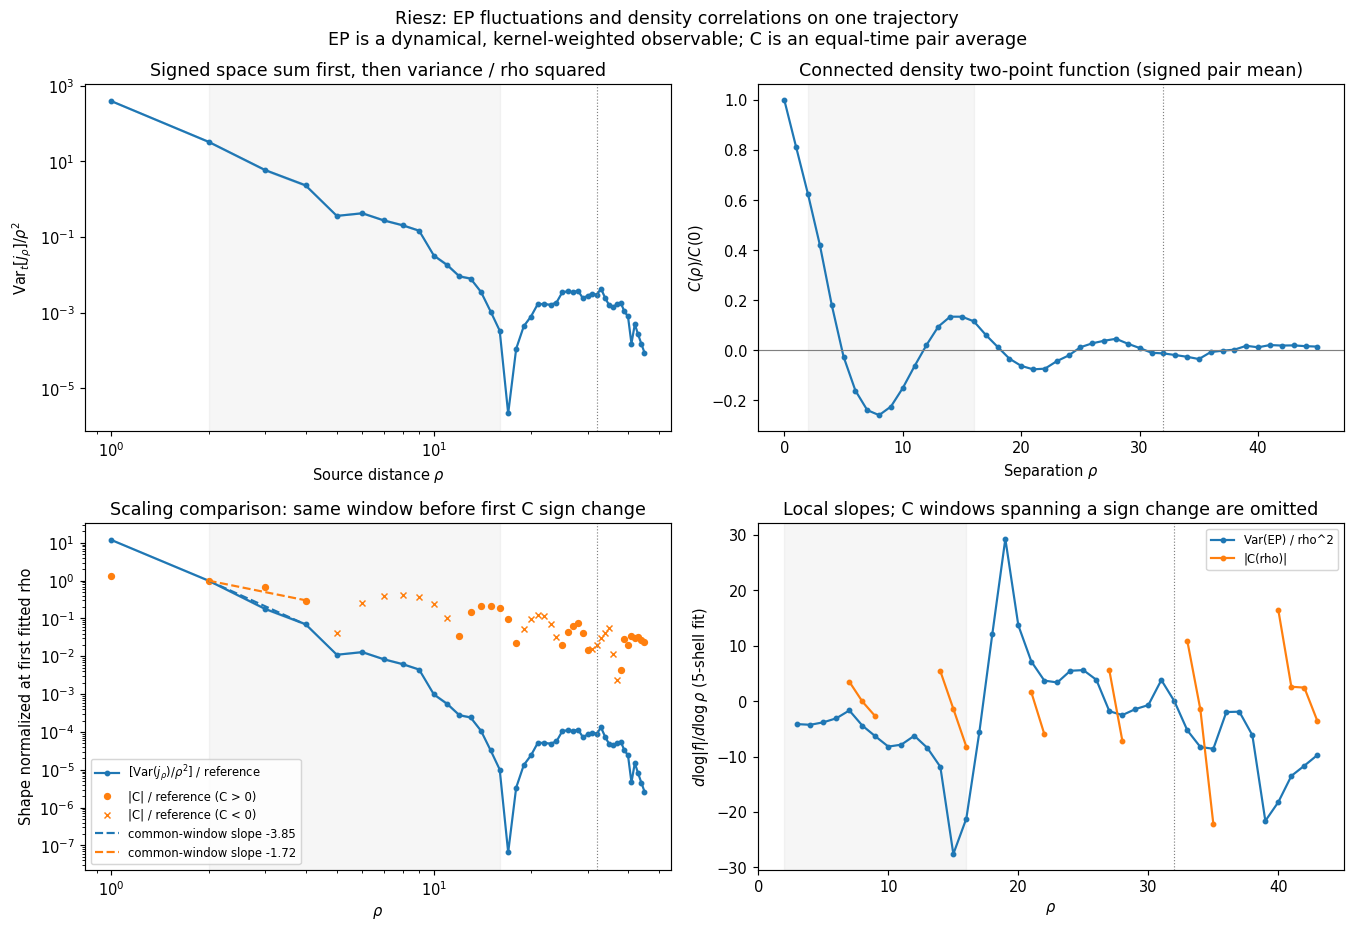

In [5]:
fig_scaling,scaling=plot_scaling_comparison(run,series,summary,OUTPUT,
    rho_min=FIT_RHO_MIN,rho_max=FIT_RHO_MAX)
display(scaling['report'])
plt.show()


## 5. 시간 구간별 변화 확인

원래 baseline의 stationarity 진단과 시간 block별 Std 곡선을 함께 본다. 관측 구간이 달라지면 variation이 바뀔 수 있으므로 이 그래프는 같은 sampling interval에서 해석한다.

[{'observable': 'F_C / area',
  'mean': -0.007582978685884974,
  'block_se': 6.799413791250216e-05,
  'drift': -7.114361160575361e-05,
  'drift_ci95': 0.000544392370129838,
  'drift_detected': False},
 {'observable': 'Var(phi)',
  'mean': 0.16141293127541032,
  'block_se': 0.000683129583441466,
  'drift': -0.0009200197723109754,
  'drift_ci95': 0.005438754551798825,
  'drift_detected': False},
 {'observable': 'mean q (S-weighted)',
  'mean': 0.6341328610604828,
  'block_se': 0.0009081702100771818,
  'drift': -0.00211553409123554,
  'drift_ci95': 0.007021805224247843,
  'drift_detected': False},
 {'observable': 'active EP / area',
  'mean': 0.09121075049163803,
  'block_se': 0.0003021319244588834,
  'drift': -0.0007262508496849902,
  'drift_ci95': 0.0023291610722282136,
  'drift_detected': False}]

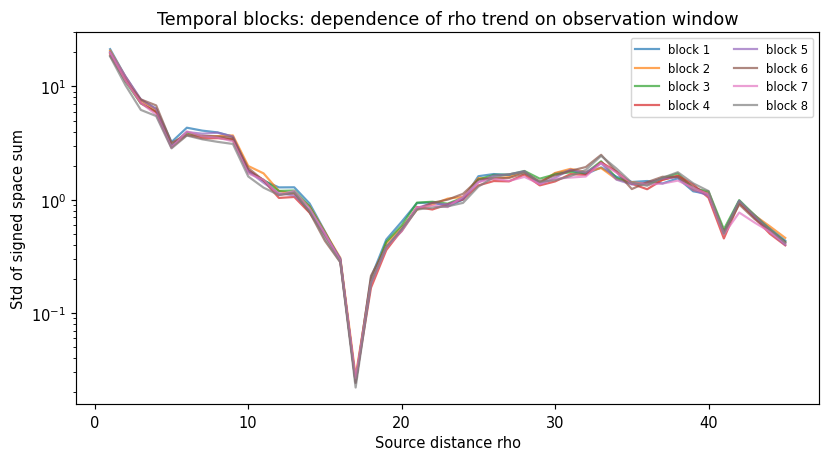

In [6]:
p=Parameters(**run.metadata['parameters'])
model=ActiveModelB(p,KernelSpec(**run.metadata['kernel']))
display(stationarity_report(model,run))
values=summary['values']
fig,ax=plt.subplots(figsize=(8,4.5))
for i,part in enumerate(np.array_split(values,BOOTSTRAP_BLOCKS)):
    ax.plot(series.rho[1:],part[:,1:].std(axis=0),alpha=.7,label=f'block {i+1}')
ax.set(xlabel='Source distance rho',ylabel='Std of signed space sum',yscale='log',
       title='Temporal blocks: dependence of rho trend on observation window')
ax.legend(ncol=2,fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT/'rho_ep_time_blocks.png',dpi=160,bbox_inches='tight')
plt.show()


## 저장 결과

`results/<kernel>_ep/`에 rho time series, mean/variance/std/CI/covariance/PSD NPZ,
거리별 variation 그림, cumulative range 비교 그림, rho trend JSON이 저장된다.
Riesz의 기본 multiplier에서 ell은 amplitude만 바꾸므로 실제 range parameter sweep은 하지 않는다.
여기의 rho/R은 source 거리 분석 축이다. Poisson/Linnik의 실제 ell sweep은 각각의 EP 노트북에서 수행한다.
